# 20261026 setup -- inspection

Plates 1-5 are 20261021's, well for well; plate 6 is a second passage plate built the same
way as plate 5, with 31 of its 102 communities shared with plate 5 (between-plate replicates
under daily dilution). Reads `outputs/` (written by `run_setup.py`) and plots it. Nothing
here writes a file.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
OUT = Path("outputs")
comm = pd.read_csv(OUT / "communities.csv")
lay = pd.read_csv(OUT / "layout.csv")
pool = pd.read_csv(OUT / "pool.csv")
tr = pd.read_csv(OUT / "strain_transfers.csv")
# validated categorical slots 1-2 (blue, orange); recessive ink and grid
C = {"core": "#2a78d6", "extended": "#eb6834"}
SH = {"this plate only": "#2a78d6", "on both passage plates": "#eb6834"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID,
                     "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
                     "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "font.size": 9})
print(open(OUT / "summary.txt").read())
print(open(OUT / "validation.txt").read())

experiment 20261026  seed 20261026
plates [1, 2, 3, 4, 5] copied well for well from 20261021; plate 6 new
pool: 133 genomes (75 core, 58 extended)

main (plates 1, 2, 3, 4): 408 communities x 3 = 1224 wells
  by module: {'small': 340, 'mid': 16, 'trio_pair': 15, 'leave_out': 9, 'large_test': 9, 'sanity_pair': 8, 'resolution_test': 6, 'trio': 5}
  by size:   {2: 23, 3: 48, 4: 43, 5: 49, 6: 43, 7: 50, 8: 43, 9: 42, 10: 42, 12: 4, 14: 3, 15: 1, 16: 3, 18: 3, 20: 4, 25: 1, 30: 1, 40: 1, 51: 1, 55: 1, 61: 1, 66: 1}
  core / extended: 285 / 123
  MPD (bp) 5/50/95%: [48.0, 231.0, 309.0]

passage plate 5: 102 communities x 3 = 306 wells
  by module: {'small': 95, 'large_test': 7}
  by size:   {3: 12, 4: 12, 5: 12, 6: 12, 7: 12, 8: 12, 9: 12, 10: 11, 15: 1, 20: 1, 25: 1, 30: 1, 40: 1, 51: 1, 61: 1}
  core / extended: 102 / 0
  MPD (bp) 5/50/95%: [85.0, 215.0, 317.0]

passage plate 6: 102 communities x 3 = 306 wells
  by module: {'small': 95, 'large_test': 7}
  by size:   {3: 12, 4: 12, 5: 12, 6

## Size x relatedness coverage

Each dot is one community of up to 10 members (larger ones are listed below).
Relatedness is the mean pairwise 16S distance between members: low = one clade, high =
across phyla. Each size is filled in three relatedness terciles, so every size spans the
range it can reach.

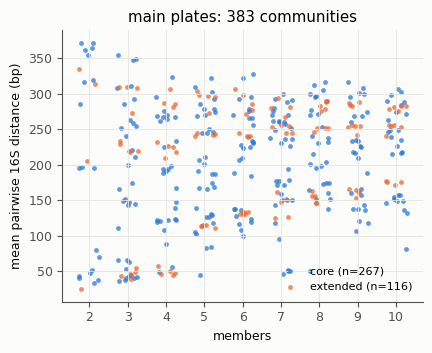

In [2]:
rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(4.4, 3.6))
c = comm[comm.blocks.str.contains("main") & (comm["size"] <= 10)]
for p in ["core", "extended"]:
    s = c[c.pool == p]
    ax.scatter(s["size"] + rng.uniform(-0.28, 0.28, len(s)), s.mpd_bp, s=12, color=C[p],
               alpha=0.75, linewidths=0, label=f"{p} (n={len(s)})")
ax.set(title=f"main plates: {c.shape[0]} communities", xlabel="members", xticks=range(2, 11),
       ylabel="mean pairwise 16S distance (bp)")
ax.legend(frameon=False, loc="lower right", fontsize=8)
fig.tight_layout()

## The two passage plates

Both hold core strains only, the same 7 large tests and the same size mix (12 communities
of each size 3-9, 11 of size 10). Orange: the 24 small communities on both plates (3 per
size, one from each relatedness tercile of plate 5's communities of that size). Their
positions on plate 6 are re-randomised under the same spacing rules, so a between-plate
difference and a within-plate replicate difference both include well position and can be
compared directly.

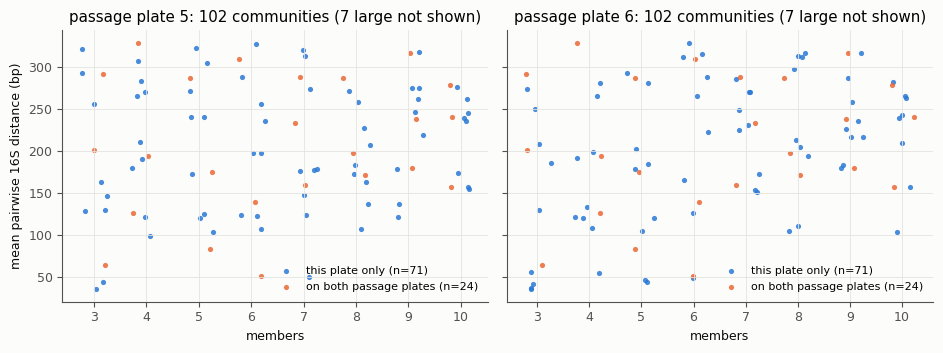

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.6), sharey=True)
for ax, p in zip(axes, [5, 6]):
    ids = set(lay[(lay.plate == p) & (lay.well_type == "community")].community_id)
    c = comm[comm.community_id.isin(ids) & (comm["size"] <= 10)]
    both = c.passage_plates == "5 6"
    for lab, s in [("this plate only", c[~both]), ("on both passage plates", c[both])]:
        ax.scatter(s["size"] + rng.uniform(-0.28, 0.28, len(s)), s.mpd_bp, s=14, color=SH[lab],
                   alpha=0.85, linewidths=0, label=f"{lab} (n={len(s)})")
    ax.set(title=f"passage plate {p}: {len(ids)} communities (7 large not shown)",
           xlabel="members", xticks=range(3, 11))
    ax.legend(frameon=False, loc="lower right", fontsize=8)
axes[0].set_ylabel("mean pairwise 16S distance (bp)")
fig.tight_layout()

In [4]:
six = comm[comm.plate6_origin != ""]
print("plate 6 by origin:")
display(six.groupby("plate6_origin")["size"].value_counts().unstack(fill_value=0))
sh = comm[comm.passage_plates == "5 6"]
w = lay[lay.plate.isin([5, 6]) & lay.community_id.isin(sh.community_id)]
wells = w.groupby(["community_id", "plate"]).well.apply(lambda s: " ".join(s)).unstack()
wells.columns = [f"wells on plate {p}" for p in wells.columns]
print("communities on both passage plates (between-plate replicates):")
display(sh.set_index("community_id")[["size", "module", "mpd_bp", "blocks"]].round(0).join(wells))
print("barcode plates (same layout at every time point):")
display(lay.groupby("plate")[["culture_plate", "block", "timepoint", "inoculated"]].first())

plate 6 by origin:


size,3,4,5,6,7,8,9,10,15,20,25,30,40,51,61
plate6_origin,,,,,,,,,,,,,,,
also on main plates,3,3,2,2,2,2,2,2,0,0,0,0,0,0,0
large test (also on plate 5),0,0,0,0,0,0,0,0,1,1,1,1,1,1,1
new,6,6,7,7,7,7,7,6,0,0,0,0,0,0,0
shared with plate 5,3,3,3,3,3,3,3,3,0,0,0,0,0,0,0


communities on both passage plates (between-plate replicates):


,size,module,mpd_bp,blocks,wells on plate 5,wells on plate 6
community_id,,,,,,
K0044,15,large_test,307.0,main;passage,B5 C12 D20,J4 L16 O4
K0045,20,large_test,277.0,main;passage,B11 J5 K16,J8 M20 N3
K0046,25,large_test,299.0,main;passage,B12 F9 G14,C14 E19 J20
K0047,30,large_test,297.0,main;passage,C8 F3 H15,B4 I9 N9
K0048,40,large_test,285.0,main;passage,C11 G18 M6,E17 G14 O15
K0049,51,large_test,290.0,main;passage,F15 I23 O20,E7 I14 K17
K0051,61,large_test,280.0,main;passage,I9 N20 O8,E14 G15 J12
K0073,4,small,194.0,main;passage,D17 L18 M20,C12 F2 M15
K0089,9,small,316.0,main;passage,G9 H12 O5,C19 E8 K15


barcode plates (same layout at every time point):


,culture_plate,block,timepoint,inoculated
plate,,,,
1,1,main,24h,True
2,2,main,24h,True
3,3,main,24h,True
4,4,main,24h,True
5,5,passage,24h,True
6,6,passage,24h,True
7,5,passage,48h,False
8,6,passage,48h,False
9,5,passage,5d,False


In [5]:
cols = ["community_id", "size", "pool", "blocks", "target_min_sep", "min_sep_bp", "mpd_bp", "member_nL", "inoculum_uL"]
print("large tests:")
display(comm[comm.module == "large_test"][cols].round(2))
print("12-20 member communities:")
display(comm[comm.module == "mid"][["community_id", "size", "pool", "mpd_bp"]].round(0))
print("resolution tests (one deliberately close pair):")
display(comm[comm.module == "resolution_test"][["community_id", "members", "close_pair", "close_pair_bp", "min_sep_bp"]])
print("trios and their pairs:")
display(comm[comm.module.isin(["trio", "trio_pair"])][["community_id", "module", "members", "parent", "pairs_measured_20260907", "mpd_bp"]].round(0))
print("sanity pairs (re-measured from 20260907):")
display(comm[comm.module == "sanity_pair"][["community_id", "members", "min_sep_bp"]])
print("leave-out series:")
display(comm[comm.module == "leave_out"][["community_id", "size", "removed"]])

large tests:


,community_id,size,pool,blocks,target_min_sep,min_sep_bp,mpd_bp,member_nL,inoculum_uL
43,K0044,15,core,main;passage,30.0,30.0,306.89,100,1.50
44,K0045,20,core,main;passage,30.0,41.0,276.61,100,2.00
45,K0046,25,core,main;passage,30.0,32.0,299.44,100,2.50
46,K0047,30,core,main;passage,30.0,30.0,296.75,100,3.00
47,K0048,40,core,main;passage,30.0,30.0,284.64,100,4.00
48,K0049,51,core,main;passage,30.0,30.0,289.66,75,3.82
49,K0050,55,extended,main,30.0,30.0,291.62,75,4.12
50,K0051,61,core,main;passage,15.0,15.0,279.62,75,4.58
51,K0052,66,extended,main,15.0,15.0,280.78,75,4.95


12-20 member communities:


,community_id,size,pool,mpd_bp
52,K0053,12,core,238.0
53,K0054,14,core,210.0
54,K0055,16,core,278.0
55,K0056,18,core,286.0
56,K0057,20,core,245.0
57,K0058,12,core,242.0
58,K0059,14,core,255.0
59,K0060,16,core,243.0
60,K0061,18,core,257.0
61,K0062,20,core,290.0


resolution tests (one deliberately close pair):


,community_id,members,close_pair,close_pair_bp,min_sep_bp
37,K0038,D18 F14 H12 H5 P2,D18-H12,13.0,13.0
38,K0039,F16 J1 J16 L8 O10,J16-L8,9.0,9.0
39,K0040,I8 M4 O7 P20 P4,P20-P4,11.0,11.0
40,K0041,G2 G21 I14 O10 P6,G2-G21,26.0,26.0
41,K0042,A20 E6 J18 K6 N15,A20-J18,27.0,27.0
42,K0043,J12 K17 K19 L2 M18,J12-M18,26.0,26.0


... (2 outputs left out)

sanity pairs (re-measured from 20260907):


,community_id,members,min_sep_bp
0,K0001,F15 G8,24.0
1,K0002,A24 O18,365.0
2,K0003,J4 K16,205.0
3,K0004,J12 K6,316.0
4,K0005,D16 F14,285.0
5,K0006,C1 D12,335.0
6,K0007,O19 P11,195.0
7,K0008,G7 O13,314.0


leave-out series:


,community_id,size,removed
28,K0029,8,NaN
29,K0030,7,M19
30,K0031,7,F2
31,K0032,7,L15
32,K0033,7,F6
33,K0034,7,C17
34,K0035,7,A11
35,K0036,7,N15
36,K0037,7,L4


## Strain usage

Wells containing each strain on the main (sequenced 24 h) plates. Extended strains appear
less often by construction: they are confined to the extended third of the communities.

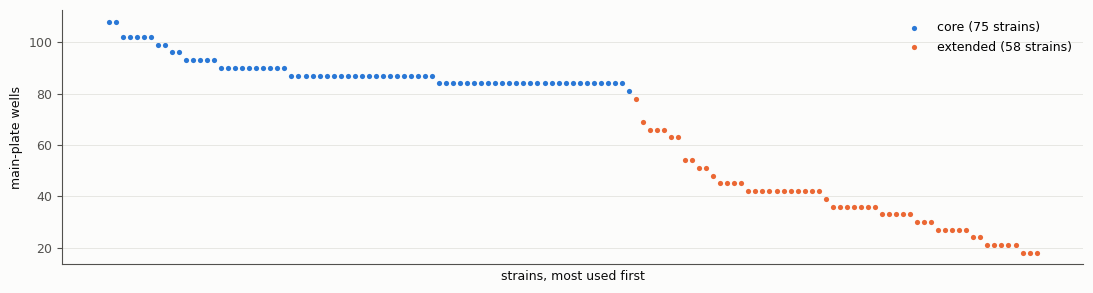

In [6]:
m = lay[(lay.block == "main") & (lay.well_type == "community")]
inc = pd.Series([x for r in m.members for x in r.split()]).value_counts()
pp = pool.set_index("strain")["pool"]
fig, ax = plt.subplots(figsize=(11, 3))
for p in ["core", "extended"]:
    s = inc[inc.index.map(pp) == p]
    x = [list(inc.index).index(k) for k in s.index]
    ax.scatter(x, s.values, s=14, color=C[p], linewidths=0, label=f"{p} ({len(s)} strains)")
ax.set(xlabel="strains, most used first", ylabel="main-plate wells", xticks=[])
ax.legend(frameon=False)
fig.tight_layout()

## Plate maps

Community size per well on every inoculated plate (blank-medium wells marked B).
Replicates of a community sit on different plates, except on the passage plates (5, 6),
where all three are on the plate but never in the same row or next to each other. Orange
rings on plates 5 and 6: communities on both passage plates.

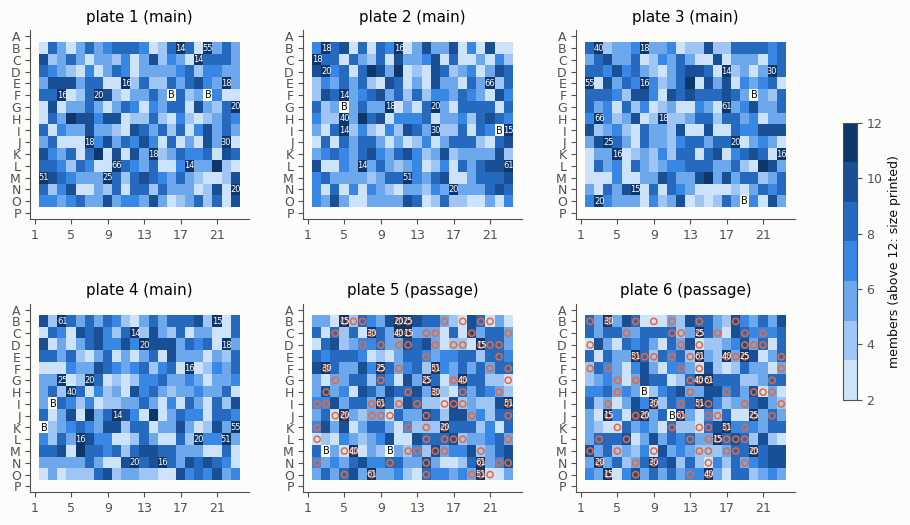

In [7]:
plates_ = sorted(lay[lay.inoculated].plate.unique())
ROWS = "ABCDEFGHIJKLMNOP"
cmap = ListedColormap(["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
shared = set(comm.community_id[comm.passage_plates == "5 6"])
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for ax, p in zip(axes.flat, plates_):
    g = lay[lay.plate == p]
    M = np.full((16, 24), np.nan)
    for r in g.itertuples():
        M[ROWS.index(r.well[0]), int(r.well[1:]) - 1] = min(r.size, 12) if r.well_type == "community" else np.nan
    im = ax.imshow(M, cmap=cmap, vmin=2, vmax=12, aspect="auto")
    for r in g[g.well_type == "blank"].itertuples():
        ax.text(int(r.well[1:]) - 1, ROWS.index(r.well[0]), "B", ha="center", va="center", fontsize=7, color=INK)
    big = g[g["size"] > 12]
    for r in big.itertuples():
        ax.text(int(r.well[1:]) - 1, ROWS.index(r.well[0]), str(r.size), ha="center", va="center", fontsize=6, color="#fcfcfb")
    if p in (5, 6):
        s = g[g.community_id.isin(shared)]
        ax.scatter(s.col - 1, s.well.str[0].map(ROWS.index), s=20, facecolors="none",
                   edgecolors=SH["on both passage plates"], linewidths=1.1)
    blk = g.block.iloc[0]
    ax.set(title=f"plate {p} ({blk})", xticks=range(0, 24, 4), xticklabels=range(1, 25, 4),
           yticks=range(16), yticklabels=list(ROWS))
    ax.grid(False)
fig.subplots_adjust(hspace=0.45, wspace=0.25, right=0.86)
cb = fig.colorbar(im, ax=list(axes.flat[:len(plates_)]), shrink=0.6, label="members (above 12: size printed)")
plt.show()

## Inoculum

Equal volume per member (100 nL; 75 nL in communities above 50 members, so no well gets
more than 5 uL = 10% of the culture). Left: preculture carried into each well. Right:
volume drawn from each source well over all six plates -- all under the 25 uL that a fill
allows, so no refill.

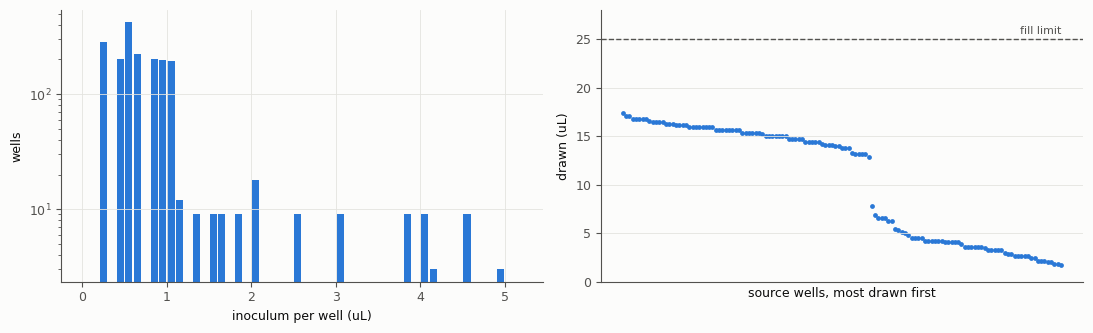

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
w = tr.groupby(["dest_plate", "dest_well"]).volume_nL.sum() / 1000
ax[0].hist(w, bins=np.linspace(0, 5.2, 53), color=C["core"], rwidth=0.85)
ax[0].set(xlabel="inoculum per well (uL)", ylabel="wells", yscale="log")
d = (tr.groupby("strain").volume_nL.sum() / 1000).sort_values(ascending=False)
ax[1].scatter(range(len(d)), d.values, s=12, color=C["core"], linewidths=0)
ax[1].axhline(25, color=MUTED, lw=1, ls="--"); ax[1].text(len(d) - 1, 25.5, "fill limit", color=MUTED, fontsize=8, ha="right")
ax[1].set(xlabel="source wells, most drawn first", ylabel="drawn (uL)", ylim=(0, 28), xticks=[])
fig.tight_layout()